#### Importing Libraries

In [1]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

#### Importing Datasets

In [2]:
df_train = pd.read_csv("../data/ml_ready/train.csv")
df_valid = pd.read_csv("../data/ml_ready/valid.csv")

#### Splitting Datasets into Train & Validation Set

In [3]:
X_train = df_train.drop('next_monthly_revenue', axis=1)
X_valid = df_valid.drop('next_monthly_revenue', axis=1)
y_train = df_train['next_monthly_revenue']
y_valid = df_valid['next_monthly_revenue']

In [4]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

actual = y_valid
naive_prediction = X_valid['monthly_revenue']

mae = mean_absolute_error(actual, naive_prediction)
mse = mean_squared_error(actual, naive_prediction)
r2 = r2_score(actual, naive_prediction)

In [5]:
result = {
    "Model": "Naive Previous Month",
    "MAE": mae,
    "RMSE": np.sqrt(mse),
    "R2 Score": r2
}

In [6]:
baseline_model = pd.DataFrame.from_dict(result, orient='index').T
baseline_model.to_csv("../data/ml_ready/model_building_summary.csv", index=False)

#### Scaling Datasets to fit Models

In [7]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_valid_scaled = scaler.transform(X_valid)

#### Baseline Models

In [8]:
actual = y_valid
naive_prediction = X_valid['monthly_revenue']

In [9]:
baseline_df = pd.concat([actual, naive_prediction], axis=1)
baseline_df.columns = ['Actual', 'Naive Prediction']
baseline_df.head()

,Actual,Naive Prediction
0,900.77,2796.29
1,2181.17,900.77
2,1143.12,2181.17
3,675.31,1143.12
4,2212.84,675.31


In [10]:
print(f"Mean Absolute Error: {mean_absolute_error(actual, naive_prediction)}")
print(f"Mean Squared Error: {mean_squared_error(actual, naive_prediction)}")
print(f"R2 Score: {r2_score(actual, naive_prediction)}")

Mean Absolute Error: 25560.7220719603
Mean Squared Error: 6358803628.605409
R2 Score: 0.620625263318898


In [11]:
print(f"Mean Absolute Error : {mae}")
print(f"Mean Squared Error : {np.sqrt(mse)}")
print(f"R2 Score : {r2}")

baseline_result = {
    "Model": "Naive Previous Month",
    "MAE": mae,
    "RMSE": np.sqrt(mse),
    "R2 Score": r2
}

baseline_model = pd.DataFrame.from_dict(result, orient='index').T

baseline_model.to_csv("../data/ml_ready/model_building_summary.csv", index=False)

Mean Absolute Error : 25560.7220719603
Mean Squared Error : 79742.10699878333
R2 Score : 0.620625263318898


#### Ridge Regression (Alpha=1)

In [12]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [13]:
ridge_model = Ridge(alpha=1)
ridge_model.fit(X_train_scaled, y_train)

,"alpha alpha: float or array-like of shape (n_targets,), default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.See :ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`for an illustration of the effect of alpha on the model coefficients.",1
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga' to

In [14]:
y_pred = ridge_model.predict(X_valid_scaled)
print(f"Ridge Model R2 Score: {r2_score(y_valid, y_pred):.4f}")
print(f"Ridge Model MAE: {mean_absolute_error(y_valid, y_pred):.4f}")
print(f"Ridge Model RMSE: {np.sqrt(mean_squared_error(y_valid, y_pred)):.4f}")

Ridge Model R2 Score: 0.8030
Ridge Model MAE: 19193.2916
Ridge Model RMSE: 57458.1571


In [15]:
result = {
    "Model": "Ridge (alpha=1)",
    "MAE": mean_absolute_error(y_valid, y_pred),
    "RMSE": np.sqrt(mean_squared_error(y_valid, y_pred)),
    "R2 Score": r2_score(y_valid, y_pred)
}

In [16]:
ridge_results = pd.DataFrame.from_dict(result, orient='index').T

In [17]:
ridge_results.head()

,Model,MAE,RMSE,R2 Score
0,Ridge (alpha=1),19193.291611,57458.157076,0.803032


In [18]:
ridge_results.to_csv("../data/ml_ready/model_building_summary.csv", mode="a", index=False, header=False)

In [19]:
pd.read_csv("../data/ml_ready/model_building_summary.csv")

,Model,MAE,RMSE,R2 Score
0,Naive Previous Month,25560.722072,79742.106999,0.620625
1,Ridge (alpha=1),19193.291611,57458.157076,0.803032


##### Ridge Regression - Hyperparameter Tuning (Finding The optimal alpha)

In [20]:
from sklearn.model_selection import GridSearchCV

param_grid = {"alpha": [0.01, 0.1, 1, 10, 100]}

ridge_grid_search = GridSearchCV(Ridge(), param_grid, cv=5, scoring='neg_mean_squared_error')

ridge_grid_search.fit(X_train_scaled, y_train)

best_ridge = ridge_grid_search.best_estimator_

print(f"Best Optimal Alpha: {ridge_grid_search.best_params_['alpha']}")

Best Optimal Alpha: 10


In [21]:
y_opt_pred = best_ridge.predict(X_valid_scaled)

print("Model Coefficients:", best_ridge.coef_)
print("Model Intercept:", best_ridge.intercept_)

Model Coefficients: [  1541.81831652  -7559.61031513  17030.18930274    797.7295806
   -692.34661959  -1671.18504094   4057.42803205   2841.13538146
   9629.72270022  10719.31746346   -445.62187883    412.52147109
  -1201.62165541    312.58112497   -833.73058527   -928.68873757
   -347.77914489  -1969.02268829   -231.53386977  -3021.58162418
  18873.55590977   -166.99267118   -198.77238809   -119.1658582
   3467.15453973    409.92695788   3866.98507059  -4012.12835673
  -1798.68188798   -344.72724005   7340.34408728   -537.47637532
 -27969.6560804   40081.98788387  30703.93609413  19291.63417833
    779.9099273   -8182.11699367]
Model Intercept: 52192.52653741901


In [22]:
ridge_results = {
    "Model": f"Ridge: {ridge_grid_search.best_params_}",
    "MAE": f"{mean_absolute_error(y_valid, y_opt_pred):.4f}",
    "RMSE": f"{np.sqrt(mean_squared_error(y_valid, y_opt_pred)):.4f}",
    "R2 Score": r2_score(y_valid, y_opt_pred)
}

In [23]:
ridge_results_alpha_10 = pd.DataFrame.from_dict(ridge_results, orient='index').T

In [24]:
ridge_results_alpha_10.to_csv("../data/ml_ready/model_building_summary.csv", mode="a", index=False, header=False)

In [25]:
pd.read_csv("../data/ml_ready/model_building_summary.csv")

,Model,MAE,RMSE,R2 Score
0,Naive Previous Month,25560.722072,79742.106999,0.620625
1,Ridge (alpha=1),19193.291611,57458.157076,0.803032
2,Ridge: {'alpha': 10},19188.812200,57437.025200,0.803177


#### Random Forest Regressor

In [26]:
from sklearn.ensemble import RandomForestRegressor

In [27]:
rf_base = RandomForestRegressor(random_state=42)

param_grid = {
    "n_estimators":[10],
    "max_depth": [None, 10,20],
    "min_samples_split": [5,10]
}

grid_search = GridSearchCV(estimator=rf_base, param_grid=param_grid, cv=3, scoring='r2', n_jobs=-1)
grid_search.fit(X_train_scaled, y_train)

best_rf_model = grid_search.best_estimator_
y_pred = best_rf_model.predict(X_valid_scaled)

In [28]:
random_forest_results = {
    "Model": f"Random Forest: {grid_search.best_params_}",
    "MAE": f"{mean_absolute_error(y_valid, y_pred):.4f}",
    "RMSE": f"{np.sqrt(mean_squared_error(y_valid, y_pred)):.4f}",
    "R2 Score": r2_score(y_valid, y_pred)
}

random_forest_results = pd.DataFrame.from_dict(random_forest_results, orient='index').T

In [29]:
random_forest_results.to_csv("../data/ml_ready/model_building_summary.csv", mode='a', index=False, header=False)

In [30]:
pd.read_csv("../data/ml_ready/model_building_summary.csv")

,Model,MAE,RMSE,R2 Score
0,Naive Previous Month,25560.722072,79742.106999,0.620625
1,Ridge (alpha=1),19193.291611,57458.157076,0.803032
2,Ridge: {'alpha': 10},19188.812200,57437.025200,0.803177
3,"Random Forest: {'max_depth': 10, 'min_samples_...",18772.354700,57773.015700,0.800867


#### Light GBM Regressor

In [31]:
from lightgbm import LGBMRegressor

In [32]:
lgb_base = LGBMRegressor(random_state=42, verbose=-1)

params_grid = {
    "n_estimators": [50,100,200],
    "learning_rate": [0.01, 0.05, 0.1],
    "num_leaves": [31,63]
}

grid_search = GridSearchCV(estimator=lgb_base, param_grid=params_grid, cv=3, scoring="r2", n_jobs=-1)
grid_search.fit(X_train_scaled, y_train)

best_lgb_model = grid_search.best_estimator_
y_pred = best_lgb_model.predict(X_valid_scaled)

In [33]:
lgb_results = {
    "Model": f"Light GBM: {grid_search.best_params_}",
    "MAE": f"{mean_absolute_error(y_valid, y_pred):.4f}",
    "RMSE": f"{np.sqrt(mean_squared_error(y_valid, y_pred)):.4f}",
    "R2 Score": f"{r2_score(y_valid, y_pred):.4f}"
}

lgb_results = pd.DataFrame.from_dict(lgb_results, orient='index').T

In [34]:
lgb_results

,Model,MAE,RMSE,R2 Score
0,"Light GBM: {'learning_rate': 0.1, 'n_estimator...",18977.4237,59070.6694,0.7918


In [35]:
lgb_results.to_csv("../data/ml_ready/model_building_summary.csv", mode='a', index=False, header=False)

In [36]:
pd.read_csv("../data/ml_ready/model_building_summary.csv")

,Model,MAE,RMSE,R2 Score
0,Naive Previous Month,25560.722072,79742.106999,0.620625
1,Ridge (alpha=1),19193.291611,57458.157076,0.803032
2,Ridge: {'alpha': 10},19188.812200,57437.025200,0.803177
3,"Random Forest: {'max_depth': 10, 'min_samples_...",18772.354700,57773.015700,0.800867
4,"Light GBM: {'learning_rate': 0.1, 'n_estimator...",18977.423700,59070.669400,0.791800


#### XGBoost Regressor

In [37]:
from xgboost import XGBRegressor

In [38]:
xgb_base = XGBRegressor(random_state=42, verbosity=0, tree_method='hist')

param_grid = {
    'n_estimators':[50,100],
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth':[3,8],          
    'subsample': [0.8, 1.0]
}


grid_search = GridSearchCV(estimator=xgb_base, param_grid=param_grid, cv=3, scoring='r2', n_jobs=-1)
grid_search.fit(X_train_scaled, y_train)

best_xgb_model = grid_search.best_estimator_
y_pred = best_xgb_model.predict(X_valid_scaled)

print(f"Best Parameters found:", grid_search.best_params_)

Best Parameters found: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100, 'subsample': 1.0}


In [39]:
xgb_results = {
    "Model": f"XGB Regressor: {grid_search.best_params_}",
    "MAE": f"{mean_absolute_error(y_valid, y_pred):.4f}",
    "RMSE": f"{np.sqrt(mean_squared_error(y_valid, y_pred)):.4f}",
    "R2 Score": f"{r2_score(y_valid, y_pred):.4f}"
}

In [40]:
xgb_results = pd.DataFrame.from_dict(xgb_results, orient='index').T

In [41]:
xgb_results

,Model,MAE,RMSE,R2 Score
0,"XGB Regressor: {'learning_rate': 0.1, 'max_dep...",18784.0403,57651.6632,0.8017


In [42]:
xgb_results.to_csv("../data/ml_ready/model_building_summary.csv", mode='a', index=False, header=False)

In [43]:
pd.read_csv("../data/ml_ready/model_building_summary.csv")

,Model,MAE,RMSE,R2 Score
0,Naive Previous Month,25560.722072,79742.106999,0.620625
1,Ridge (alpha=1),19193.291611,57458.157076,0.803032
2,Ridge: {'alpha': 10},19188.812200,57437.025200,0.803177
3,"Random Forest: {'max_depth': 10, 'min_samples_...",18772.354700,57773.015700,0.800867
4,"Light GBM: {'learning_rate': 0.1, 'n_estimator...",18977.423700,59070.669400,0.791800
5,"XGB Regressor: {'learning_rate': 0.1, 'max_dep...",18784.040300,57651.663200,0.801700


#### Light GBM Regressor (5- Fold CV + Neg_Absolute_Mean_Error)

In [44]:
lgb_base = LGBMRegressor(random_state=42, verbose=-1)

params_grid = {
    "n_estimators": [50,100,200],
    "learning_rate": [0.01, 0.05, 0.1],
    "num_leaves": [31,63]
}

lgb_grid_search = GridSearchCV(estimator=lgb_base, param_grid=params_grid, cv=5, scoring="neg_mean_absolute_error", n_jobs=-1)
lgb_grid_search.fit(X_train_scaled, y_train)

best_lgb_model = lgb_grid_search.best_estimator_
y_pred = best_lgb_model.predict(X_valid_scaled)

In [45]:
lgb_results = {
    "Model": f"Light GBM: {lgb_grid_search.best_params_}",
    "MAE": f"{mean_absolute_error(y_valid, y_pred):.4f}",
    "RMSE": f"{np.sqrt(mean_squared_error(y_valid, y_pred)):.4f}",
    "R2 Score": f"{r2_score(y_valid, y_pred):.4f}"
}

lgb_results = pd.DataFrame.from_dict(lgb_results, orient='index').T

In [46]:
lgb_grid_search.best_params_

{'learning_rate': 0.05, 'n_estimators': 200, 'num_leaves': 31}

In [47]:
lgb_results

,Model,MAE,RMSE,R2 Score
0,"Light GBM: {'learning_rate': 0.05, 'n_estimato...",18812.0910,58241.4747,0.7976


In [48]:
lgb_results.to_csv("../data/ml_ready/model_building_summary.csv", mode='a', index=False, header=False)

In [49]:
pd.read_csv("../data/ml_ready/model_building_summary.csv")

,Model,MAE,RMSE,R2 Score
0,Naive Previous Month,25560.722072,79742.106999,0.620625
1,Ridge (alpha=1),19193.291611,57458.157076,0.803032
2,Ridge: {'alpha': 10},19188.812200,57437.025200,0.803177
3,"Random Forest: {'max_depth': 10, 'min_samples_...",18772.354700,57773.015700,0.800867
4,"Light GBM: {'learning_rate': 0.1, 'n_estimator...",18977.423700,59070.669400,0.791800
5,"XGB Regressor: {'learning_rate': 0.1, 'max_dep...",18784.040300,57651.663200,0.801700
6,"Light GBM: {'learning_rate': 0.05, 'n_estimato...",18812.091000,58241.474700,0.797600


#### XGB Regressor (5 Fold CV + Neg Absolute Mean Error)

In [50]:
xgb_base = XGBRegressor(random_state=42, verbosity=0, tree_method='hist')

param_grid = {
    'n_estimators':[50,100],
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth':[3,8],          
    'subsample': [0.8, 1.0]
}


xgb_grid_search = GridSearchCV(estimator=xgb_base, param_grid=param_grid, cv=5, scoring='neg_mean_absolute_error', n_jobs=-1)
xgb_grid_search.fit(X_train_scaled, y_train)

best_xgb_model = xgb_grid_search.best_estimator_
y_pred = best_xgb_model.predict(X_valid_scaled)

print(f"Best Parameters found:", xgb_grid_search.best_params_)

Best Parameters found: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100, 'subsample': 0.8}


In [51]:
xgb_results = {
    "Model": f"XGB Regressor: {xgb_grid_search.best_params_}",
    "MAE": f"{mean_absolute_error(y_valid, y_pred):.4f}",
    "RMSE": f"{np.sqrt(mean_squared_error(y_valid, y_pred)):.4f}",
    "R2 Score": f"{r2_score(y_valid, y_pred):.4f}"
}

In [52]:
xgb_results = pd.DataFrame.from_dict(xgb_results, orient='index').T

In [53]:
xgb_results

,Model,MAE,RMSE,R2 Score
0,"XGB Regressor: {'learning_rate': 0.1, 'max_dep...",18997.7061,57743.0213,0.8011


In [54]:
xgb_results.to_csv("../data/ml_ready/model_building_summary.csv", mode='a', index=False, header=False)

In [55]:
pd.read_csv("../data/ml_ready/model_building_summary.csv")

,Model,MAE,RMSE,R2 Score
0,Naive Previous Month,25560.722072,79742.106999,0.620625
1,Ridge (alpha=1),19193.291611,57458.157076,0.803032
2,Ridge: {'alpha': 10},19188.812200,57437.025200,0.803177
3,"Random Forest: {'max_depth': 10, 'min_samples_...",18772.354700,57773.015700,0.800867
4,"Light GBM: {'learning_rate': 0.1, 'n_estimator...",18977.423700,59070.669400,0.791800
5,"XGB Regressor: {'learning_rate': 0.1, 'max_dep...",18784.040300,57651.663200,0.801700
6,"Light GBM: {'learning_rate': 0.05, 'n_estimato...",18812.091000,58241.474700,0.797600
7,"XGB Regressor: {'learning_rate': 0.1, 'max_dep...",18997.706100,57743.021300,0.801100


#### Random Forest Regressor (5 Fold CV + Neg Mean Absolute Error)

In [56]:
rf_base = RandomForestRegressor(random_state=42)

param_grid = {
    "n_estimators":[10],
    "max_depth": [None, 10,20],
    "min_samples_split": [5,10]
}

rf_grid_search = GridSearchCV(estimator=rf_base, param_grid=param_grid, cv=5, scoring='neg_mean_absolute_error', n_jobs=-1)
rf_grid_search.fit(X_train_scaled, y_train)

best_rf_model = rf_grid_search.best_estimator_
y_pred = best_rf_model.predict(X_valid_scaled)

In [57]:
rf_grid_search.best_params_

{'max_depth': None, 'min_samples_split': 10, 'n_estimators': 10}

In [58]:
random_forest_results = {
    "Model": f"Random Forest: {grid_search.best_params_}",
    "MAE": f"{mean_absolute_error(y_valid, y_pred):.4f}",
    "RMSE": f"{np.sqrt(mean_squared_error(y_valid, y_pred)):.4f}",
    "R2 Score": r2_score(y_valid, y_pred)
}

random_forest_results = pd.DataFrame.from_dict(random_forest_results, orient='index').T

In [59]:
random_forest_results

,Model,MAE,RMSE,R2 Score
0,"Random Forest: {'learning_rate': 0.1, 'max_dep...",19304.1347,58406.4831,0.796476


In [60]:
random_forest_results.to_csv("../data/ml_ready/model_building_summary.csv", mode='a', index=False, header=False)

In [61]:
pd.read_csv("../data/ml_ready/model_building_summary.csv")

,Model,MAE,RMSE,R2 Score
0,Naive Previous Month,25560.722072,79742.106999,0.620625
1,Ridge (alpha=1),19193.291611,57458.157076,0.803032
2,Ridge: {'alpha': 10},19188.812200,57437.025200,0.803177
3,"Random Forest: {'max_depth': 10, 'min_samples_...",18772.354700,57773.015700,0.800867
4,"Light GBM: {'learning_rate': 0.1, 'n_estimator...",18977.423700,59070.669400,0.791800
5,"XGB Regressor: {'learning_rate': 0.1, 'max_dep...",18784.040300,57651.663200,0.801700
6,"Light GBM: {'learning_rate': 0.05, 'n_estimato...",18812.091000,58241.474700,0.797600
7,"XGB Regressor: {'learning_rate': 0.1, 'max_dep...",18997.706100,57743.021300,0.801100
8,"Random Forest: {'learning_rate': 0.1, 'max_dep...",19304.134700,58406.483100,0.796476


#### Freezing Parameters

In [62]:
final_df_summary = {
    "Model": ["Ridge", "Random Forest", "XGBRegressor", "LightGBM"],
    "CV": ["5 Fold"] * 4,
    "Scoring": ["neg MAE"] * 4,
    "Best Parameters": [ridge_grid_search.best_params_, rf_grid_search.best_params_, xgb_grid_search.best_params_,lgb_grid_search.best_params_]
}

In [63]:
final_df_summary = pd.DataFrame.from_dict(final_df_summary, orient='index').T

In [64]:
final_df_summary

,Model,CV,Scoring,Best Parameters
0,Ridge,5 Fold,neg MAE,{'alpha': 10}
1,Random Forest,5 Fold,neg MAE,"{'max_depth': None, 'min_samples_split': 10, '..."
2,XGBRegressor,5 Fold,neg MAE,"{'learning_rate': 0.1, 'max_depth': 3, 'n_esti..."
3,LightGBM,5 Fold,neg MAE,"{'learning_rate': 0.05, 'n_estimators': 200, '..."


In [65]:
final_df_summary.to_csv("../data/ml_ready/freeze_parameters.csv", index=False)

### Model Re-Training

In [66]:
ridge_model = Ridge(alpha=10, random_state=42)

#### Random Forest Regressor with Hyperparameter Tuning

In [67]:
rf_model = RandomForestRegressor(
    # Forest Structure & Framework
    n_estimators= 2000, 
    bootstrap= True, 
    max_samples = 0.7, 

    # Tree Depth & Size Control    
    max_depth= 10, 
    min_samples_split = 3, 
    min_samples_leaf= 5, 
    max_leaf_nodes= None,

    # Feature Splitting & Splitting Criteria                  
    max_features = 0.5, 
    criterion = "squared_error", 
    min_impurity_decrease= 0.0,

    ## Execution & Performance
    n_jobs = -1, 
    random_state= 42,

    ## Validation & Training Control 
    oob_score = True, 
    warm_start= True, 
    verbose = 0, 
    ccp_alpha=0.02  
)

#### XGBoost Regressor With Hyper parameter Tuning

In [68]:
xgb_model = XGBRegressor(
    ## Boosting Control & Framework
    n_estimators=100,
    learning_rate=0.1,
    booster="gbtree",

    ## Tree Growth & Depth Control
    max_depth=7,
    max_leaves=5, 
    gamma=5,

    ## Stochastic & Sampling Parameters
    subsample=0.8,
    colsample_bytree=0.3,

    ## Regression Strategy & Performance
    objective='reg:squarederror',
    eval_metric="mae",
    tree_method="hist",
    n_jobs=-1,
    random_state=42
)

#### Light GBM Regressor with Hyperparameter Tuning

In [69]:
lightgbm_model = LGBMRegressor(
    n_estimators=1000,
    learning_rate=0.05,
    data_sample_strategy= "goss",
    num_leaves=100,
    max_depth=5,
    min_child_samples=20,
    objective="mae",
    n_jobs=-1,
    verbose=0,
    random_state=42
)

In [70]:
ridge_model.fit(X_train_scaled, y_train)
ridge_y_pred = ridge_model.predict(X_valid_scaled)

lightgbm_model.fit(X_train_scaled, y_train)
lightgbm_y_pred = lightgbm_model.predict(X_valid_scaled)

rf_model.fit(X_train_scaled, y_train)
rf_y_pred = rf_model.predict(X_valid_scaled)

xgb_model.fit(X_train_scaled, y_train)
xgb_y_pred = xgb_model.predict(X_valid_scaled)

[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No f

In [71]:
model = {
    "Model": ["Ridge", "Random Forest", "XGB Regressor", "LightGBM"],
    "MAE": [round(mean_absolute_error(y_valid, ridge_y_pred), 2), 
            round(mean_absolute_error(y_valid, rf_y_pred), 2), 
            round(mean_absolute_error(y_valid, xgb_y_pred), 2), 
            round(mean_absolute_error(y_valid, lightgbm_y_pred), 2)],

    "RMSE": [round(np.sqrt(mean_squared_error(y_valid, ridge_y_pred)),2), 
             round(np.sqrt(mean_squared_error(y_valid, rf_y_pred)),2),
             round(np.sqrt(mean_squared_error(y_valid, xgb_y_pred)),2),
             round(np.sqrt(mean_squared_error(y_valid, lightgbm_y_pred)),2)],

    "R2 Score": [round(r2_score(y_valid, ridge_y_pred), 2), 
            round(r2_score(y_valid, rf_y_pred), 2), 
            round(r2_score(y_valid, xgb_y_pred), 2), 
            round(r2_score(y_valid, lightgbm_y_pred), 2)]
}

In [72]:
model = pd.DataFrame.from_dict(model, orient='index').T
model

,Model,MAE,RMSE,R2 Score
0,Ridge,19188.81,57437.03,0.8
1,Random Forest,18461.23,56299.38,0.81
2,XGB Regressor,19028.05,57933.44,0.8
3,LightGBM,18642.08,58044.31,0.8


#### Business/Error Analysis

##### Random Forest Regressor

###### Create Actual vs Predicted Dataset

In [73]:
random_forest_regressor_error_analysis = {
    "Actual Revenue": y_valid,
    "Predicted Revenue": rf_y_pred,
    "Error": (y_valid - rf_y_pred),
    "Absolute Error": abs(y_valid - rf_y_pred),
    "Percentage Error": (abs(y_valid - rf_y_pred)/y_valid)*100
}

In [74]:
rf_error_analysis = pd.DataFrame(random_forest_regressor_error_analysis)
rf_error_analysis.head()

,Actual Revenue,Predicted Revenue,Error,Absolute Error,Percentage Error
0,900.77,2175.086118,-1274.316118,1274.316118,141.469645
1,2181.17,1777.608628,403.561372,403.561372,18.502060
2,1143.12,2069.709353,-926.589353,926.589353,81.057925
3,675.31,1639.970105,-964.660105,964.660105,142.847004
4,2212.84,1718.884459,493.955541,493.955541,22.322244


In [75]:
rf_error_analysis.to_csv("Error Analysis.csv", index=False)

In [76]:
print(f"Mean Absolute Error: {rf_error_analysis["Absolute Error"].mean()}")
print(f"Median Absolute Error: {rf_error_analysis["Absolute Error"].median()}")
print(f"Minimum Absolute Error: {rf_error_analysis["Absolute Error"].min()}")
print(f"Maximum Absolute Error: {rf_error_analysis["Absolute Error"].max()}")
print(f"Std.Dev: {rf_error_analysis["Absolute Error"].std()}")

Mean Absolute Error: 18461.228505186267
Median Absolute Error: 5158.23778849931
Minimum Absolute Error: 0.3514208514316124
Maximum Absolute Error: 1426461.8567214874
Std.Dev: 53187.71921519139


###### Biggest Mistakes - Over/Under Prediction

In [77]:
rf_error_analysis.sort_values(by='Error', ascending=False).head()

,Actual Revenue,Predicted Revenue,Error,Absolute Error,Percentage Error
19161,2429583.75,1.003122e+06,1.426462e+06,1.426462e+06,58.712191
19133,2193048.00,8.884937e+05,1.304554e+06,1.304554e+06,59.485900
19179,2472525.00,1.199113e+06,1.273412e+06,1.273412e+06,51.502508
19182,2050785.00,1.013660e+06,1.037125e+06,1.037125e+06,50.572097
19119,1621158.00,6.837769e+05,9.373811e+05,9.373811e+05,57.821700


In [78]:
rf_error_analysis.sort_values(by='Error', ascending=True).head()

,Actual Revenue,Predicted Revenue,Error,Absolute Error,Percentage Error
19132,105732.0,9.877871e+05,-882055.113574,882055.113574,834.236668
19135,432432.0,1.286162e+06,-853730.026014,853730.026014,197.425266
20468,325458.0,1.085214e+06,-759756.437217,759756.437217,233.442237
20454,86782.5,8.040922e+05,-717309.706726,717309.706726,826.560317
20462,521640.0,1.188033e+06,-666392.832170,666392.832170,127.749565


###### Error Behaviour by Month

In [79]:
rf_error_analysis["month_number"] = X_valid["month_number"]

In [80]:
rf_error_analysis.head()

,Actual Revenue,Predicted Revenue,Error,Absolute Error,Percentage Error,month_number
0,900.77,2175.086118,-1274.316118,1274.316118,141.469645,1
1,2181.17,1777.608628,403.561372,403.561372,18.502060,2
2,1143.12,2069.709353,-926.589353,926.589353,81.057925,3
3,675.31,1639.970105,-964.660105,964.660105,142.847004,4
4,2212.84,1718.884459,493.955541,493.955541,22.322244,5


In [81]:
rf_error_analysis.groupby(by='month_number').agg({"Absolute Error": ["mean"]})

,Absolute Error
,mean
month_number,
1,18422.383747
2,17754.922176
3,18126.171380
4,18995.720723
5,17490.855700
6,17651.960057
7,20039.109552
8,18784.269301


###### RF Vs Naive Baseline

In [82]:
print(f"Mean Absolute Error: {mean_absolute_error(actual, naive_prediction)}")
print(f"Mean Squared Error: {mean_squared_error(actual, naive_prediction)}")
print(f"R2 Score: {r2_score(actual, naive_prediction)}")

Mean Absolute Error: 25560.7220719603
Mean Squared Error: 6358803628.605409
R2 Score: 0.620625263318898


In [83]:
print(f"Mean Absolute Error: {mean_absolute_error(y_valid, rf_y_pred)}")
print(f"Mean Squared Error: {mean_squared_error(y_valid, rf_y_pred)}")
print(f"R2 Score: {r2_score(y_valid, rf_y_pred)}")

Mean Absolute Error: 18461.228505186267
Mean Squared Error: 3169620439.0487614
R2 Score: 0.8108962016009157


In [84]:
print(f"% MAE Reduction: {str(round((mean_absolute_error(y_valid, rf_y_pred) - mean_absolute_error(actual, naive_prediction))*100/mean_absolute_error(actual, naive_prediction),2)) + str("%")}")

% MAE Reduction: -27.78%


In [85]:
rf_error_reduction = round((mean_absolute_error(y_valid, rf_y_pred) - mean_absolute_error(actual, naive_prediction))*100/mean_absolute_error(actual, naive_prediction),2)

###### Error Distribution Analysis

In [86]:
error_distribution_analysis = {
    "25th_percentile": rf_error_analysis["Absolute Error"].quantile(0.25),
    "Median": rf_error_analysis["Absolute Error"].median(),
    "75th_percentile": rf_error_analysis["Absolute Error"].quantile(0.75),
    "90th_percentile": rf_error_analysis["Absolute Error"].quantile(0.9),
    "95th_percentile": rf_error_analysis["Absolute Error"].quantile(0.95),
    "99th_percentile": rf_error_analysis["Absolute Error"].quantile(0.99)
}

In [87]:
error_distribution_analysis = pd.DataFrame.from_dict(error_distribution_analysis, orient='index').T

In [88]:
error_distribution_analysis

,25th_percentile,Median,75th_percentile,90th_percentile,95th_percentile,99th_percentile
0,1788.901403,5158.237788,13586.325294,35019.598534,74259.743926,255448.942431


In [89]:
import matplotlib.pyplot as plt
%matplotlib inline

Text(0.5, 1.0, 'Actual VS Predicted Relationship')

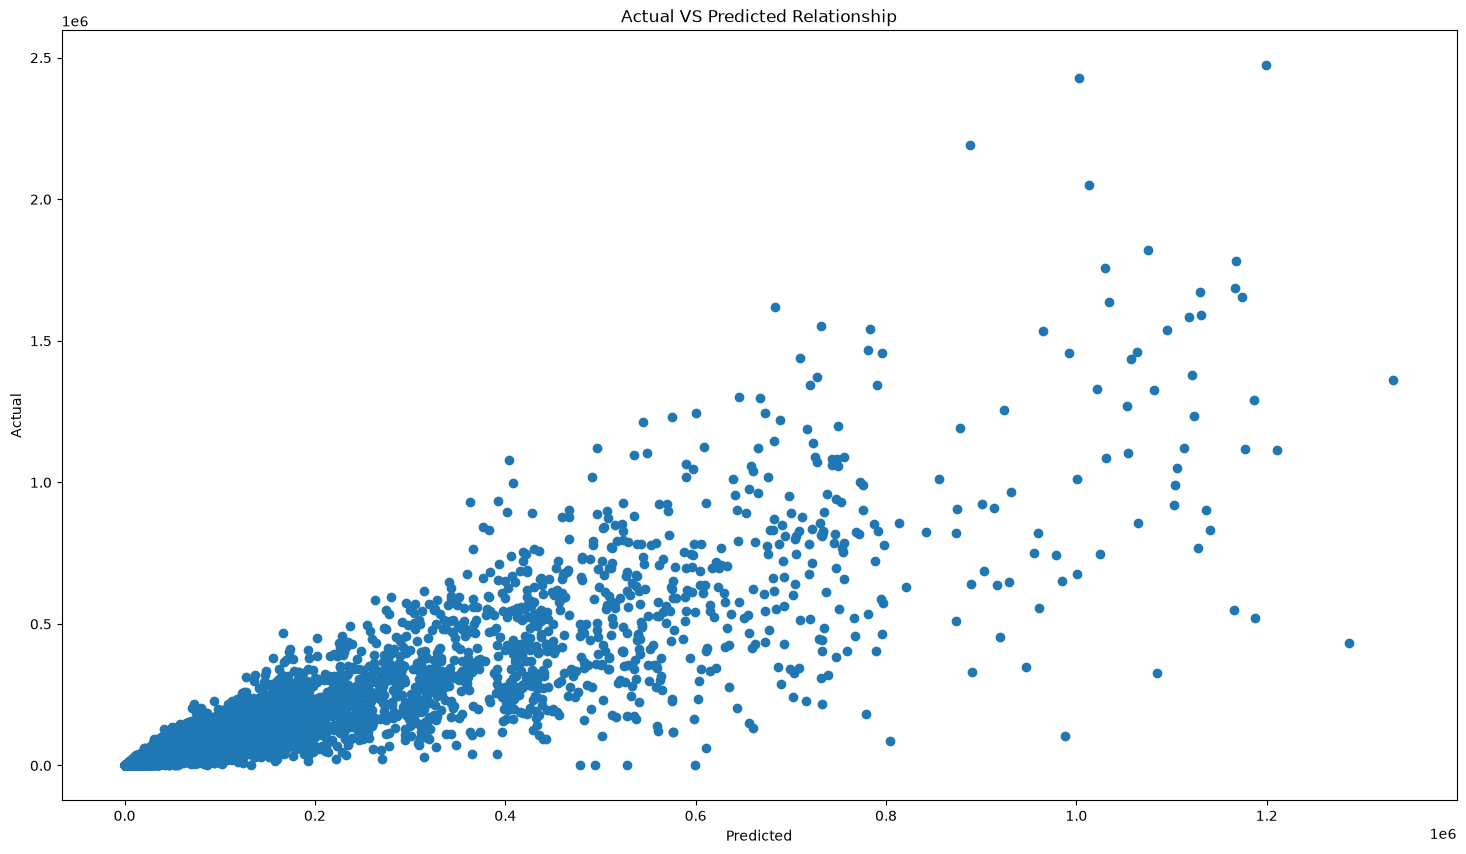

In [90]:
plt.figure(figsize=[18,10])
plt.scatter(rf_y_pred, y_valid)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Actual VS Predicted Relationship")

###### Business Interpretation

Random Forest currently performs strongest among the evaluated models, with 2024 validation MAE of approximately ₹9.8K.
Compared with the Naive previous-month baseline, RF reduces MAE by approximately 61.28%.
The median absolute error (~₹2.6K) is substantially below the mean (~₹9.8K), while the upper percentiles increase sharply, indicating most predictions have relatively smaller errors but a smaller number of extreme errors significantly increase overall MAE.
The model generally tracks actual revenue well, but some extreme high/low revenue observations are harder to predict accurately.
Monthly MAE remains in a relatively similar range (~₹9.2K–₹10.4K), so there isn't an obvious single month where the model consistently breaks down.

##### Light GBM Regressor

###### Create Actual vs Predicted Dataset

In [91]:
lightgbm_regressor_error_analysis = {
    "Actual Revenue": y_valid,
    "Predicted Revenue": lightgbm_y_pred,
    "Error": (y_valid - lightgbm_y_pred),
    "Absolute Error": abs(y_valid - lightgbm_y_pred),
    "Percentage Error": (abs(y_valid - lightgbm_y_pred)/y_valid)*100
}

In [92]:
lgbm_error_analysis = pd.DataFrame(lightgbm_regressor_error_analysis)
lgbm_error_analysis.head()

,Actual Revenue,Predicted Revenue,Error,Absolute Error,Percentage Error
0,900.77,1778.559406,-877.789406,877.789406,97.448783
1,2181.17,2224.655497,-43.485497,43.485497,1.993678
2,1143.12,2039.343454,-896.223454,896.223454,78.401520
3,675.31,1812.101117,-1136.791117,1136.791117,168.336189
4,2212.84,1681.268136,531.571864,531.571864,24.022155


In [93]:
lgbm_error_analysis.to_csv("../data/ml_ready/LightBM_Error Analysis.csv", index=False)

In [94]:
print(f"Mean Absolute Error: {lgbm_error_analysis["Absolute Error"].mean()}")
print(f"Median Absolute Error: {lgbm_error_analysis["Absolute Error"].median()}")
print(f"Minimum Absolute Error: {lgbm_error_analysis["Absolute Error"].min()}")
print(f"Maximum Absolute Error: {lgbm_error_analysis["Absolute Error"].max()}")
print(f"Std.Dev: {lgbm_error_analysis["Absolute Error"].std()}")

Mean Absolute Error: 18642.077605294024
Median Absolute Error: 5151.193454198636
Minimum Absolute Error: 1.3124533468262598
Maximum Absolute Error: 1509402.0591032566
Std.Dev: 54970.48180070557


###### Biggest Mistakes - Over/Under Prediction

In [95]:
lgbm_error_analysis.sort_values(by='Error', ascending=False).head()

,Actual Revenue,Predicted Revenue,Error,Absolute Error,Percentage Error
19179,2472525.00,9.631229e+05,1.509402e+06,1.509402e+06,61.046989
19161,2429583.75,1.073468e+06,1.356116e+06,1.356116e+06,55.816808
19133,2193048.00,9.442285e+05,1.248819e+06,1.248819e+06,56.944465
19182,2050785.00,9.739289e+05,1.076856e+06,1.076856e+06,52.509457
19119,1621158.00,6.432563e+05,9.779017e+05,9.779017e+05,60.321184


In [96]:
lgbm_error_analysis.sort_values(by='Error', ascending=True).head()

,Actual Revenue,Predicted Revenue,Error,Absolute Error,Percentage Error
19132,105732.0,9.502535e+05,-844521.450958,844521.450958,798.737800
19901,452655.0,1.179748e+06,-727093.246956,727093.246956,160.628569
20454,86782.5,8.065812e+05,-719798.723226,719798.723226,829.428425
19135,432432.0,1.090711e+06,-658278.781204,658278.781204,152.227120
20445,0.0,6.080993e+05,-608099.257310,608099.257310,inf


###### Error behaviour by month

In [97]:
lgbm_error_analysis["month_number"] = X_valid["month_number"]

In [98]:
lgbm_error_analysis.groupby(by='month_number').agg({"Absolute Error": ["mean"]})

,Absolute Error
,mean
month_number,
1,18357.361956
2,18053.063707
3,17854.330822
4,18916.430962
5,17846.382496
6,17858.880390
7,20660.460707
8,19260.176909


###### LGBM vs Naive Baseline

In [99]:
print(f"% MAE Reduction: {str(round((mean_absolute_error(y_valid, lightgbm_y_pred) - mean_absolute_error(actual, naive_prediction))*100/mean_absolute_error(actual, naive_prediction),2)) + str("%")}")

% MAE Reduction: -27.07%


In [100]:
lgbm_error_reduction = round((mean_absolute_error(y_valid, lightgbm_y_pred) - mean_absolute_error(actual, naive_prediction))*100/mean_absolute_error(actual, naive_prediction),2)

###### Error Distribution Analysis

In [101]:
lgbm_error_distribution_analysis = {
    "25th_percentile": lgbm_error_analysis["Absolute Error"].quantile(0.25),
    "Median": lgbm_error_analysis["Absolute Error"].median(),
    "75th_percentile": lgbm_error_analysis["Absolute Error"].quantile(0.75),
    "90th_percentile": lgbm_error_analysis["Absolute Error"].quantile(0.9),
    "95th_percentile": lgbm_error_analysis["Absolute Error"].quantile(0.95),
    "99th_percentile": lgbm_error_analysis["Absolute Error"].quantile(0.99)
}

In [102]:
lgbm_error_distribution_analysis = pd.DataFrame.from_dict(lgbm_error_distribution_analysis, orient='index').T

In [103]:
lgbm_error_distribution_analysis

,25th_percentile,Median,75th_percentile,90th_percentile,95th_percentile,99th_percentile
0,1775.72187,5151.193454,13458.585302,35234.545178,73406.68079,261000.653858


#### Final Summary

In [104]:
final_conclusion = {
    "Metric": ["Random Forest", "LightGBM"],
    "MAE": [round(mean_absolute_error(y_valid, rf_y_pred),2), round(mean_absolute_error(y_valid, lightgbm_y_pred),2)],
    "RMSE": [round(np.sqrt(mean_squared_error(y_valid, rf_y_pred)),2), round(np.sqrt(mean_squared_error(y_valid, lightgbm_y_pred)),2)],
    "R2": [r2_score(y_valid, rf_y_pred), r2_score(y_valid, lightgbm_y_pred)],
    "MAE Reduction vs Naive": [str(rf_error_reduction) + str("%"), str(lgbm_error_reduction) + str("%")],
    "Median Absolute Error": [round(rf_error_analysis["Absolute Error"].quantile(0.5),2), round(lgbm_error_analysis["Absolute Error"].quantile(0.5),2)]
}

final_conclusion = pd.DataFrame.from_dict(final_conclusion, orient='index')
final_conclusion.columns = final_conclusion.iloc[0]
final_conclusion = final_conclusion[1:]
final_conclusion

Metric,Random Forest,LightGBM
MAE,18461.23,18642.08
RMSE,56299.38,58044.31
R2,0.810896,0.798992
MAE Reduction vs Naive,-27.78%,-27.07%
Median Absolute Error,5158.24,5151.19


### Feature Importance

In [105]:
light_gbm_feature_imp = pd.DataFrame(lightgbm_model.feature_importances_*100, index=X_train.columns, columns=["Importances"]).sort_values(by="Importances", ascending=False)

In [106]:
rf_feature_imp = pd.DataFrame(rf_model.feature_importances_*100, index=X_train.columns, columns=["Importances"]).sort_values(by="Importances", ascending=False)

In [108]:
light_gbm_feature_imp.to_csv("../data/ml_ready/light_gbm_feature_importance.csv")
rf_feature_imp.to_csv("../data/ml_ready/random_forest_feature_importance.csv")

### Saving Final Model to JobLib

In [109]:
import joblib

joblib.dump(scaler, "../models/scaler.joblib")
joblib.dump(rf_model, "../models/random_forest_model.joblib")
joblib.dump(lightgbm_model, "../models/light_gbm_model.joblib")

['../models/light_gbm_model.joblib']